<a href="https://colab.research.google.com/github/annihlj/AIOps_PromptGuard/blob/main/notebooks/train_llm_lora_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prompt Guard: Milestone 2C, small LLM (Qwen3) with LoRA (Google Colab)

**The starting point.** Our encoder (XLM-RoBERTa + LoRA, run 2 `xlmr_lora_benign_templates`) is the best model so far:
macro F1 0.966 on the validation set and 548 of 600 own German prompts correct. Its weak spot is **block**: it
catches only **179 of 200** block prompts of our own, mostly because passwords written in everyday style
("Das WLAN-Passwort ist Kaffeebohne#42") are classified as warn. It needs about 85 ms (p95) per prompt on the laptop.

**The question.** Our professor suggested trying a small local **LLM** (large language model). An LLM was
pre-trained on much more text than the encoder. Does this bigger language knowledge give better results, above all
a higher **block recall on our own prompts**? And is it worth the loss in speed?

**The fair comparison.** Everything is **exactly** as in encoder run 2, only the model is different:

| Part | Encoder run 2 | This notebook |
|---|---|---|
| Base model | `xlm-roberta-base` (~280 M weights) | **`Qwen/Qwen3-0.6B`** (~600 M weights), optional `Qwen3-1.7B` |
| Head | new classification layer, 3 outputs | the same (`AutoModelForSequenceClassification`, 3 classes) |
| LoRA | `query`, `value`; r = 16, alpha = 32, dropout 0.1 | `q_proj`, `k_proj`, `v_proj`, `o_proj`; r = 16, alpha = 32, dropout 0.1 |
| Training data | ai4privacy sample (2,500 per class and language, seed 42) + harmless + 12,000 short prompts | **the same** (checked with fingerprints and the number of texts) |
| Validation, threshold rule, `evaluate`, own prompts, short-prompt validation | | **the same** (shared code in `src/train_utils.py`) |

The code that is the same for both notebooks is in `src/`: `encoder_utils.py` (load a model, predict) and
`train_utils.py` (data, sample, evaluation). So it cannot be different by accident.

**Two switches** in chapter 3:

| Switch | Values | Meaning |
|---|---|---|
| `MODEL_SIZE` | `"0.6B"` (default) / `"1.7B"` | 1.7B is loaded with 4 bits (QLoRA), otherwise it does not fit on the free GPU |
| `QUICK_TEST` | `True` / `False` | `True`: mini run (about 1,000 texts, 1 epoch, small validation) to check that everything runs. It is logged as `..._quicktest` with the tag `quick_test=true`, not as a normal run |

**Rules:** train only on train, choose settings on validation, never touch a test set, our own prompts are only
used for evaluation.

**Structure**
0. Before you start · 1. Project and packages · 2. Setup · 3. Settings · 4. Data · 5. Training sample ·
6. Helper functions · 7. Model with LoRA · 8. Training · 9. Validation and block threshold · 10. Own prompts ·
10b. Short-prompt validation · 11. Confusion matrices · 12. Save the model · 13. Response time on the CPU ·
14. Comparison with SVM and encoder · 15. MLflow · 16. Check MLflow and download a local copy · 17. Conclusion

How an LLM works and how it differs from the encoder: [`docs/algorithms/en/05_llm_lora.md`](../docs/algorithms/en/05_llm_lora.md).

## 0. Before you start (once)

1. **The code must be on GitHub.** The notebook downloads the project with `git clone` (branch `main`).
2. **GPU:** *Runtime → Change runtime type → T4 GPU*.
3. **DagsHub token as Colab secrets** (key icon on the left, then "Add new secret", switch on "Notebook access"):
   - `MLFLOW_TRACKING_USERNAME` = your DagsHub user name
   - `MLFLOW_TRACKING_PASSWORD` = your DagsHub token (DagsHub → Settings → Tokens)

   Never write the token into a cell. (The same secrets as for the encoder notebook.)
4. **First a quick test:** leave `QUICK_TEST = True` in chapter 3 and choose *Runtime → Run all* (about 10 to 15 minutes,
   most of it is building the data). If everything runs through, set `QUICK_TEST = False` and *Run all* again.
5. At the end the browser downloads a ZIP with the model (e.g. `qwen3_0.6b_lora_templates.zip`).

Duration of the real run on a T4: Qwen3-0.6B needs roughly 4 to 6 times more computing per text than the encoder
(11 minutes), so expect **about 1 to 1.5 hours**. `1.7B` with QLoRA takes several hours and can reach the time limit
of free Colab.

## 1. Project and packages

The same as in the encoder notebook: we download the project from GitHub and install the packages from
`requirements.txt` (same versions as on our laptops), **except torch** (Colab's torch matches its GPU driver).
New: also `requirements-train.txt`, which only contains `bitsandbytes` (4-bit loading for `MODEL_SIZE = "1.7B"`;
it is only needed on a GPU, so it is not in `requirements.txt`).
This cell must run **before** anything else is imported, so the new package versions are used.

When the notebook runs on a computer of its own (not in Colab), it uses the local project folder instead.

In [1]:
import shutil
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/annihlj/AIOps_PromptGuard.git"
BRANCH = "main"


def read_requirements(path, keep=None):
    # lines like "transformers==5.24.1" (no comments); keep = only these package names
    lines = [line.strip() for line in path.read_text().splitlines() if line.strip() and not line.startswith("#")]
    return [line for line in lines if keep is None or line.split("==")[0].strip() in keep]


if IN_COLAB:
    # fail early if the GPU runtime was forgotten
    if shutil.which("nvidia-smi") is None:
        raise RuntimeError("No GPU. Runtime -> Change runtime type -> T4 GPU, then run again.")
    PROJECT_DIR = Path("/content/AIOps_PromptGuard")
    if not PROJECT_DIR.exists():
        subprocess.run(["git", "clone", "--quiet", "--branch", BRANCH, REPO_URL, str(PROJECT_DIR)], check=True)
    # From requirements.txt we only install what Colab does not have, with exactly our versions.
    # Not torch: Colab's own torch matches its GPU driver.
    NEEDED = {"transformers", "peft", "accelerate", "mlflow", "python-dotenv"}
    packages = (read_requirements(PROJECT_DIR / "requirements.txt", NEEDED)
                + read_requirements(PROJECT_DIR / "requirements-train.txt"))     # bitsandbytes
    print("Installing:", packages)
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *packages], check=True)
else:
    PROJECT_DIR = Path("..").resolve()     # notebook started from the folder notebooks/

# The exact code version, logged to MLflow (reproducibility)
GIT_COMMIT = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=PROJECT_DIR,
                            capture_output=True, text=True, check=False).stdout.strip()
print("Project:", PROJECT_DIR, "| git commit:", GIT_COMMIT)

Installing: ['mlflow==3.18.0', 'python-dotenv==1.2.4', 'transformers==5.24.1', 'peft==0.22.0', 'accelerate==1.16.0', 'bitsandbytes==0.50.2']
Project: /content/AIOps_PromptGuard | git commit: 2012228


## 2. Setup

Imports, GPU check, MLflow (shared DagsHub server, same experiment `promptguard` as all other runs) and
Google Drive (off). The shared functions come from `src/encoder_utils.py` and `src/train_utils.py`.

In [3]:
import gc
import json
import os
import platform
import time

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import peft
import torch
import transformers
import yaml
from peft import LoraConfig, TaskType, get_peft_model, prepare_model_for_kbit_training
from sklearn.metrics import ConfusionMatrixDisplay, f1_score, recall_score
from transformers import DataCollatorWithPadding, EarlyStoppingCallback, Trainer, TrainingArguments

sys.path.append(str(PROJECT_DIR / "src"))
from data_utils import split_fingerprint
from harmless_data import harmless_fingerprint
from encoder_utils import (CLASSES, CONFIG_FILE, LORA_LAYERS, load_base_model, load_model, load_tokenizer,
                           predict_proba, predict_with_threshold)

# ---- GPU
if torch.cuda.is_available():
    DEVICE = "cuda"
    DEVICE_NAME = f"cuda ({torch.cuda.get_device_name(0)})"
else:
    DEVICE = "cpu"
    DEVICE_NAME = f"cpu ({platform.processor() or platform.machine()})"
    print("WARNING: no GPU, training on the CPU takes many hours.")
print("Device:", DEVICE_NAME)
print(f"Python {platform.python_version()} | torch {torch.__version__} | transformers {transformers.__version__}"
      f" | peft {peft.__version__}")

# ---- MLflow: in Colab the login comes from the Colab secrets, on a laptop from .env (like the other notebooks)
if IN_COLAB:
    from google.colab import userdata
    os.environ["MLFLOW_TRACKING_URI"] = "https://dagshub.com/annihlj/AIOps_PromptGuard.mlflow"
    os.environ["MLFLOW_TRACKING_USERNAME"] = userdata.get("MLFLOW_TRACKING_USERNAME")
    os.environ["MLFLOW_TRACKING_PASSWORD"] = userdata.get("MLFLOW_TRACKING_PASSWORD")
else:
    from dotenv import load_dotenv
    load_dotenv(PROJECT_DIR / ".env")
if os.getenv("MLFLOW_TRACKING_URI"):
    mlflow.set_tracking_uri(os.environ["MLFLOW_TRACKING_URI"])
else:
    mlflow.set_tracking_uri(f"sqlite:///{(PROJECT_DIR / 'mlflow.db').as_posix()}")
mlflow.set_experiment("promptguard")      # also tests the login: fails here, not after the training
print("MLflow:", mlflow.get_tracking_uri())

# ---- Google Drive: optional backup. Turned off, the model is saved to MLflow anyway.
USE_DRIVE = False
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

Device: cuda (Tesla T4)
Python 3.13.16 | torch 2.14.1+cu130 | transformers 5.24.1 | peft 0.22.0
MLflow: https://dagshub.com/annihlj/AIOps_PromptGuard.mlflow


## 3. Settings

**`MODEL_SIZE`** chooses the LLM, **`QUICK_TEST`** the mini run (see the top of the notebook). All other settings are
logged to MLflow.

| Setting | Value | Why |
|---|---|---|
| `BASE_MODEL_REVISION` | fixed commit hash | models on Hugging Face can be updated; with the hash everybody downloads exactly the same model |
| LoRA r / alpha / dropout | 16 / 32 / 0.1 | the same as the encoder |
| LoRA layers | `q_proj`, `k_proj`, `v_proj`, `o_proj` | all four projections of the attention layers (common setting for LLMs) |
| learning rate | 1e-4 | half of the encoder (2e-4): the LLM is bigger, smaller steps are safer |
| epochs | max. 3, early stopping on validation macro F1 | the same as the encoder |
| batch size | 16 × 2 (0.6B) or 8 × 4 (1.7B) | *gradient accumulation*: 2 (or 4) small batches are added up before one update step, so the effective batch is 32 like the encoder, but it fits into the 16 GB of the T4 |
| `MAX_LENGTH` | 128 tokens | the same as the encoder |

**Quantization (only `1.7B`).** The base model is stored with 4 bits per weight instead of 32 (QLoRA). That makes it
about 8 times smaller, so it fits on the T4. The LoRA matrices are still trained in normal precision.
Qwen3-0.6B fits without it, so it is **not** quantized (more exact).

In [4]:
MODEL_SIZE = "0.6B"     # "0.6B" (LoRA, default) or "1.7B" (QLoRA: base model in 4 bits, GPU only)
QUICK_TEST = False       # True = mini run to check that everything works; False = the real run

# Qwen3 models with a fixed revision (= commit hash on Hugging Face, checked on 2026-11-28)
QWEN_MODELS = {
    "0.6B": {"base_model": "Qwen/Qwen3-0.6B", "revision": "c1899de289a04d12100db370d81485cdf75e47ca",
             "quantization": None, "batch_size": 16, "grad_accum": 2},
    "1.7B": {"base_model": "Qwen/Qwen3-1.7B", "revision": "70d244cc86ccca08cf5af4e1e306ecf908b1ad5e",
             "quantization": "4bit", "batch_size": 8, "grad_accum": 4},
}
MODEL_FAMILY = "llm"
BASE_MODEL = QWEN_MODELS[MODEL_SIZE]["base_model"]
BASE_MODEL_REVISION = QWEN_MODELS[MODEL_SIZE]["revision"]
QUANTIZATION = QWEN_MODELS[MODEL_SIZE]["quantization"]
BATCH_SIZE = QWEN_MODELS[MODEL_SIZE]["batch_size"]
GRAD_ACCUM = QWEN_MODELS[MODEL_SIZE]["grad_accum"]          # effective batch = 32, like the encoder
if QUANTIZATION and DEVICE != "cuda":
    raise RuntimeError("MODEL_SIZE = '1.7B' uses 4-bit quantization, which needs a GPU.")

# The same training data as encoder run 2 ("xlmr_lora_benign_templates")
USE_TEMPLATE_PII = True
TRAIN_DATA = "train+benign+template_pii"
ENCODER_RUN_NAME = "xlmr_lora_benign_templates"
ENCODER_RUN_ID = "722a01b2e847445f81c44a83d37cad97"   # MLflow run of encoder run 2, for the comparison in chapter 14

RUN_NAME = f"qwen3_{MODEL_SIZE.lower()}_{'qlora' if QUANTIZATION else 'lora'}_templates"
if QUICK_TEST:
    RUN_NAME += "_quicktest"

LORA_R, LORA_ALPHA, LORA_DROPOUT = 16, 32, 0.1
LEARNING_RATE = 1e-4
EPOCHS = 1 if QUICK_TEST else 3          # maximum; early stopping can end earlier
EARLY_STOPPING_PATIENCE = 1              # stop if the validation macro F1 does not improve for 1 epoch
MAX_LENGTH = 128                         # tokens per text; longer texts are cut off
EVAL_BATCH_SIZE = 64
N_PER_CLASS_AND_LANGUAGE = 2500          # the same sample as the encoder
SEED = 42

# Quick test: only a small part of the data (the full data is still loaded and checked)
QUICK_TRAIN_SIZE, QUICK_VAL_SIZE = 1000, 2000
N_LATENCY = 50 if QUICK_TEST else 1000   # prompts for the response time (chapter 13)

# Expected fingerprints of the data (see README) and the size of the training sample of encoder run 2
EXPECTED_SPLIT_FINGERPRINT = "6afd6a257de1"
EXPECTED_HARMLESS_FINGERPRINT = "32d24c900fd7"
EXPECTED_TEMPLATE_FINGERPRINT = "bb97fd4d3e90"   # data/short_prompts.csv
EXPECTED_TRAIN_SIZE = 45_845                     # texts in the training sample of encoder run 2

MODEL_DIR = PROJECT_DIR / "models" / RUN_NAME                  # the trained adapter (not in Git)
OUT_DIR = PROJECT_DIR / "models" / f"{RUN_NAME}_outputs"       # pictures and tables for MLflow
CHECKPOINT_DIR = Path("/content/checkpoints") if IN_COLAB else PROJECT_DIR / "models" / "checkpoints"
DRIVE_DIR = Path("/content/drive/MyDrive/promptguard/models")

with open(PROJECT_DIR / "config" / "policy.yaml", encoding="utf-8") as f:
    POLICY_VERSION = str(yaml.safe_load(f)["version"])

transformers.set_seed(SEED)      # sets the seed for Python, numpy and torch at once
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
print(f"Model: {BASE_MODEL} ({QUANTIZATION or 'no quantization'}) | run: {RUN_NAME} | policy: {POLICY_VERSION}"
      f" | quick test: {QUICK_TEST}")

Model: Qwen/Qwen3-0.6B (no quantization) | run: qwen3_0.6b_lora_templates_quicktest | policy: 0.1 | quick test: True


## 4. Data

The same as encoder run 2: the raw ai4privacy files, the harmless prompts and the short prompts are not in Git, so
we create them with the **same scripts** as on the laptop. The fingerprints prove that we get exactly the same data.

`load_train_val()` (`src/train_utils.py`) is the code of chapter 4 of the encoder notebook: one table for train and
one for validation, with a column `origin` (ai4privacy, harmless, template_pii). **No test set is loaded.**
The validation part of the short prompts is only used to evaluate (chapter 10b), it is **not** part of the validation
set.

We pick the 1,000 prompts for the response time (chapter 13) here, from the **full** validation set, so they are the
same as for the SVM and the encoder (also in the quick test, which uses only the first 50 of them).

In [5]:
data_dir = PROJECT_DIR / "data"
if not (data_dir / "german_pii_52k.jsonl").exists():
    subprocess.run([sys.executable, "src/download_data.py"], cwd=PROJECT_DIR, check=True)
for script, file in [("src/harmless_data.py", "harmless_prompts.csv"), ("src/short_prompts.py", "short_prompts.csv")]:
    if not (data_dir / file).exists():
        print(f"Building {file} (a few minutes) ...")
        # the scripts print a long report (spot check); we only show the last lines
        result = subprocess.run([sys.executable, script], cwd=PROJECT_DIR, check=True,
                                capture_output=True, text=True, encoding="utf-8")
        print("\n".join(result.stdout.splitlines()[-2:]))

from short_prompts import short_prompts_fingerprint   # import after the file exists

SPLIT_FINGERPRINT = split_fingerprint()
HARMLESS_FINGERPRINT = harmless_fingerprint()
TEMPLATE_FINGERPRINT = short_prompts_fingerprint()
print("Split fingerprint:   ", SPLIT_FINGERPRINT)
print("Harmless fingerprint:", HARMLESS_FINGERPRINT)
print("Template fingerprint:", TEMPLATE_FINGERPRINT)
assert SPLIT_FINGERPRINT == EXPECTED_SPLIT_FINGERPRINT, "splits.csv is different from the team version"
assert HARMLESS_FINGERPRINT == EXPECTED_HARMLESS_FINGERPRINT, (
    "harmless_prompts.csv is different from the team version. Fix: upload your local "
    "data/harmless_prompts.csv into the folder data/ of the project (folder icon on the left) "
    "and run this cell again.")
assert TEMPLATE_FINGERPRINT == EXPECTED_TEMPLATE_FINGERPRINT, (
    "short_prompts.csv is different from the team version (see README). Fix: upload your local "
    "data/short_prompts.csv into the folder data/ of the project and run this cell again.")

Building harmless_prompts.csv (a few minutes) ...
Saved 4,984 prompts to /content/AIOps_PromptGuard/data/harmless_prompts.csv
Fingerprint: 32d24c900fd7
Building short_prompts.csv (a few minutes) ...
Saved 13,200 prompts to /content/AIOps_PromptGuard/data/short_prompts.csv
Fingerprint: bb97fd4d3e90
Split fingerprint:    6afd6a257de1
Harmless fingerprint: 32d24c900fd7
Template fingerprint: bb97fd4d3e90


In [6]:
from train_utils import load_train_val

train, val, template_val = load_train_val(use_short_prompts=True)
own = pd.read_csv(PROJECT_DIR / "data" / "own_prompts.csv")     # our 600 German prompts, ONLY for evaluation

# the same 1,000 prompts as svm_linear.ipynb and the encoder (always from the FULL validation set)
latency_sample = val["source_text"].sample(1000, random_state=SEED).tolist()[:N_LATENCY]

if QUICK_TEST:
    # only a random part of the validation set, so the quick test is fast
    val = val.sample(QUICK_VAL_SIZE, random_state=SEED).reset_index(drop=True)
    print(f"QUICK TEST: validation reduced to {len(val):,} texts")

is_pii = (val["origin"] == "ai4privacy").to_numpy()      # validation rows from ai4privacy
is_harmless = ~is_pii                                     # validation rows from the harmless prompts
is_de = (val["language"] == "de").to_numpy()
_ = gc.collect()

display(pd.crosstab(val["origin"], val["decision"], margins=True).rename_axis("VALIDATION"))

QUICK TEST: validation reduced to 2,000 texts


decision,allow,block,warn,All
VALIDATION,,,,
ai4privacy,174,623,1175,1972
harmless,28,0,0,28
All,202,623,1175,2000


## 5. Training sample

`sample_train()` is chapter 5 of the encoder notebook: **2,500 texts per class and language** from ai4privacy train
(seed 42), **plus all harmless train prompts, plus all 12,000 short train prompts**. The check below proves that it is
the same number of texts as in encoder run 2 (45,845).

Quick test: then we take only 1,000 random texts of this sample.

In [7]:
from train_utils import sample_train

train_sample = sample_train(train, N_PER_CLASS_AND_LANGUAGE, SEED, use_short_prompts=True)
assert len(train_sample) == EXPECTED_TRAIN_SIZE, f"{len(train_sample)} training texts, encoder run 2 had {EXPECTED_TRAIN_SIZE}"
N_HARMLESS_TRAIN = int((train_sample["origin"] == "harmless").sum())
# number of short prompts per class (logged to MLflow, the same parameters as encoder run 2)
N_TEMPLATE_TRAIN = train_sample.loc[train_sample["origin"] == "template_pii", "decision"].value_counts().to_dict()
if QUICK_TEST:
    train_sample = train_sample.sample(QUICK_TRAIN_SIZE, random_state=SEED).reset_index(drop=True)
    print(f"QUICK TEST: training sample reduced to {len(train_sample):,} texts")
del train
_ = gc.collect()

display(pd.crosstab([train_sample["origin"], train_sample["decision"]], train_sample["language"], margins=True)
        .rename_axis(["TRAIN SAMPLE", ""]))
print(f"Training texts: {len(train_sample):,}")

QUICK TEST: training sample reduced to 1,000 texts


language             de   en   fr   it   All
TRAIN SAMPLE                                
ai4privacy   allow   48   58   52   41   199
             block   55   62   45   56   218
             warn    70   58   60   42   230
harmless     allow   36   48    7    3    94
template_pii allow   35   48    0    0    83
             block   42   42    0    0    84
             warn    54   38    0    0    92
All                 340  354  164  142  1000

Training texts: 1,000


## 6. Helper functions

Not copied this time, but imported from `src/train_utils.py` (the code is identical to chapter 6 of the encoder
notebook): `evaluate`, `harmless_shares`, `threshold_sweep`, `choose_threshold`, `plot_sweep`, plus `own_metrics` and
`template_rows` for chapters 10 and 10b. `predict_with_threshold` (`src/encoder_utils.py`) uses the same rule as all
other models: **block if p(block) ≥ t**, otherwise the more likely of allow / warn.

New: `proba()` calculates the probabilities on the GPU in half precision (*fp16*). For 31,000 validation texts this
is several times faster, and the result is practically the same.

In [8]:
from train_utils import (TARGET_FALSE_BLOCK, TARGET_RECALL_BLOCK, THRESHOLDS, choose_threshold, evaluate,
                         harmless_shares, own_metrics, own_rows, own_rows_from_metrics, plot_sweep, template_rows,
                         threshold_sweep)

print("Thresholds:", THRESHOLDS, "| targets: recall block >=", TARGET_RECALL_BLOCK,
      "| allow blocked <=", TARGET_FALSE_BLOCK)


def proba(texts, batch_size=EVAL_BATCH_SIZE):
    # probabilities (allow, warn, block) of the model in memory; on the GPU in half precision (faster)
    with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEVICE == "cuda")):
        return predict_proba(model, tokenizer, list(texts), MAX_LENGTH, batch_size=batch_size)

Thresholds: [0.5, 0.45, 0.4, 0.35, 0.3, 0.25, 0.2, 0.15, 0.1, 0.05] | targets: recall block >= 0.95 | allow blocked <= 0.05


## 7. Model with LoRA

**Tokenizer.** Qwen3 has its own tokenizer (other word pieces than XLM-R). An LLM normally writes one text at a time
and does not need a *padding token* (used to fill up shorter texts in a batch). Qwen3 has one (`<|endoftext|>`), but it
is missing in the model config, so we write it there (`load_base_model` does this).

**Why the padding token matters.** An LLM reads from left to right: each token only sees the tokens **before** it.
So only the **last** token has seen the whole prompt, and the classification head uses this last token. To find
the last *real* token in a padded batch, the model looks for the first padding token.

**Model.** `AutoModelForSequenceClassification` = Qwen3 plus a **new classification head** `score` with 3 outputs
(allow, warn, block), random at the start. The part of Qwen3 that writes text (the language-model head) is not used.

**LoRA** freezes all weights of Qwen3 and adds small matrices (rank 16) to the four attention projections
`q_proj`, `k_proj`, `v_proj`, `o_proj` of every layer. Trained: the LoRA matrices + the head (`modules_to_save`).
With `1.7B`, the frozen weights are additionally stored in 4 bits (`prepare_model_for_kbit_training` prepares the
model for this, e.g. it turns on *gradient checkpointing*: saves GPU memory, costs time).

In [9]:
tokenizer = load_tokenizer(BASE_MODEL, BASE_MODEL_REVISION, MODEL_FAMILY)
print("Padding token:", repr(tokenizer.pad_token), tokenizer.pad_token_id, "| padding side:", tokenizer.padding_side)
label2id = {c: i for i, c in enumerate(CLASSES)}      # allow = 0, warn = 1, block = 2


class PromptDataset(torch.utils.data.Dataset):
    """Texts -> token numbers (done once at the start) + the label as a number (same as the encoder)."""

    def __init__(self, texts, decisions):
        self.encodings = tokenizer(list(texts), truncation=True, max_length=MAX_LENGTH)
        self.labels = [label2id[d] for d in decisions]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        # one training example: token numbers, attention mask and the label
        item = {key: values[i] for key, values in self.encodings.items()}
        item["labels"] = self.labels[i]
        return item


train_ds = PromptDataset(train_sample["source_text"], train_sample["decision"])
val_ds = PromptDataset(val["source_text"], val["decision"])
cut_off = np.mean([len(ids) >= MAX_LENGTH for ids in train_ds.encodings["input_ids"]])
print(f"Train texts longer than {MAX_LENGTH} tokens (cut off): {cut_off:.1%}")

base_model = load_base_model(BASE_MODEL, BASE_MODEL_REVISION, CLASSES, model_family=MODEL_FAMILY,
                             pad_token_id=tokenizer.pad_token_id, quantization=QUANTIZATION)
if QUANTIZATION:
    base_model = prepare_model_for_kbit_training(base_model, use_gradient_checkpointing=True)

lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,       # sequence classification = one label per text
    r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT,
    **LORA_LAYERS[BASE_MODEL],        # target_modules (q/k/v/o_proj) + modules_to_save (head "score")
)
model = get_peft_model(base_model, lora_config)
model.print_trainable_parameters()
# (trainable, all) weights; counts 4-bit weights correctly
N_TRAINABLE, N_PARAMS_TOTAL = model.get_nb_trainable_parameters()

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (3 outputs left out)

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

[transformers] Qwen3ForSequenceClassification LOAD REPORT from: Qwen/Qwen3-0.6B
Key            | Status     | 
---------------+------------+-
lm_head.weight | UNEXPECTED | 
score.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 4,590,592 || all params: 600,643,584 || trainable%: 0.7643


/usr/local/lib/python3.13/dist-packages/peft/import_utils.py:195: UserWarning: Found an incompatible version of torchao. Found version 0.10.0, but only versions above 0.16.0 are supported. torchao support in PEFT is disabled; if you want to use a torchao-quantized model with PEFT, please upgrade torchao.
  warnings.warn(


## 8. Training

The same `Trainer` settings as the encoder (validation macro F1 after every epoch, early stopping,
`load_best_model_at_end`, `fp16` on the GPU, MLflow logging by the Trainer off: we log ourselves in chapter 15).
New: `gradient_accumulation_steps` (see chapter 3) and, only for `1.7B`, gradient checkpointing.

If the loss shows `nan`: the calculation in half precision overflowed. Then set `fp16=False` (slower) and run again.

In [10]:
def compute_metrics(eval_pred):
    # called by the Trainer after every epoch on the validation set (rule: highest probability wins)
    logits, labels = eval_pred
    return {"macro_f1": f1_score(labels, logits.argmax(axis=1), average="macro")}


args = TrainingArguments(
    output_dir=str(CHECKPOINT_DIR),
    num_train_epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRAD_ACCUM,      # BATCH_SIZE x GRAD_ACCUM = 32 texts per update step
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    warmup_steps=0.06,                 # a number < 1 = share of all steps: small learning rate for the first 6 %
    weight_decay=0.01,
    eval_strategy="epoch",             # validate after every epoch ...
    save_strategy="epoch",             # ... and save a checkpoint
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=2,
    fp16=(DEVICE == "cuda"),
    gradient_checkpointing=bool(QUANTIZATION),
    logging_steps=10 if QUICK_TEST else 100,
    seed=SEED,
    data_seed=SEED,
    report_to="none",
)
trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=DataCollatorWithPadding(tokenizer),   # fills texts of one batch up to the same length
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=EARLY_STOPPING_PATIENCE)],
)

start = time.perf_counter()
trainer.train()
TRAIN_MINUTES = (time.perf_counter() - start) / 60
EPOCHS_TRAINED = float(trainer.state.epoch)

# validation macro F1 after every epoch
history = pd.DataFrame([h for h in trainer.state.log_history if "eval_macro_f1" in h])
history = history[["epoch", "eval_macro_f1", "eval_loss"]].round(4)
display(history)
print(f"Training took {TRAIN_MINUTES:.0f} min, {EPOCHS_TRAINED:g} epochs. "
      f"Best epoch: {history.loc[history['eval_macro_f1'].idxmax(), 'epoch']:g}")
if DEVICE == "cuda":
    print(f"Max. GPU memory: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")

/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing` is deprecated and will be removed in v6. Use `activation_checkpointing` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)


Epoch,Training Loss,Validation Loss,Macro F1
1,1.963923,1.056127,0.444301


,epoch,eval_macro_f1,eval_loss
0,1.0,0.4443,1.0561


Training took 1 min, 1 epochs. Best epoch: 1
Max. GPU memory: 7.5 GB


## 9. Validation and block threshold

The same as the encoder: probabilities for the **combined** validation set (ai4privacy + real harmless prompts), all
thresholds, the same rule to choose one. For comparison also the default rule (highest probability wins, "argmax").

,threshold,macro_f1,recall_block,recall_warn,recall_allow,false_block_allow,false_block_warn,meets both targets
0,0.50,0.4251,0.3339,0.5379,0.5693,0.0297,0.1268,False
1,0.45,0.4445,0.4173,0.5140,0.5693,0.0396,0.1736,False
2,0.40,0.4413,0.4960,0.4715,0.5149,0.1139,0.2511,False
3,0.35,0.4334,0.5778,0.4170,0.4703,0.1931,0.3430,False
4,0.30,0.4172,0.6742,0.3489,0.4109,0.2871,0.4417,False
5,0.25,0.4009,0.7769,0.2740,0.3762,0.3713,0.5523,False
6,0.20,0.3569,0.8587,0.1949,0.2772,0.5198,0.6689,False
7,0.15,0.3127,0.9310,0.1234,0.1980,0.6683,0.7872,False
8,0.10,0.2648,0.9727,0.0604,0.1386,0.7921,0.8885,False
9,0.05,0.2004,0.9920,0.0102,0.0594,0.9307,0.9728,False


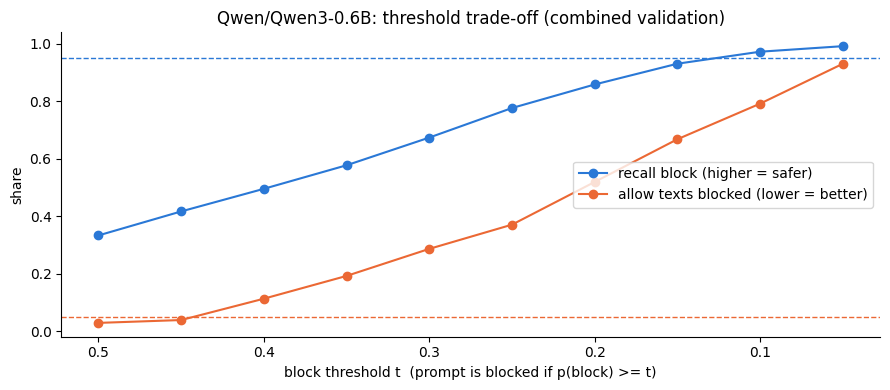

Chosen threshold: 0.45 (both targets not reachable; best recall block with <= 5 % false alarms)


,threshold 0.45,argmax
macro_f1,0.4445,0.4443
recall_block,0.4173,0.5136
recall_warn,0.5140,0.4638
recall_allow,0.5693,0.5198
false_block_allow,0.0396,0.1089
false_block_warn,0.1736,0.2638
harmless_to_block,0.0357,0.0357
harmless_to_warn,0.0357,0.0357
de_recall_block,0.2237,0.3487


In [11]:
model.eval()
val_proba = proba(val["source_text"])

all_rows = np.ones(len(val), dtype=bool)
sweep = threshold_sweep(val_proba, CLASSES, val["decision"], all_rows)
display(sweep.round(4))
plot_sweep(sweep, f"{BASE_MODEL}: threshold trade-off (combined validation)")

BLOCK_THRESHOLD, threshold_reason = choose_threshold(sweep)
val_pred = predict_with_threshold(val_proba, CLASSES, BLOCK_THRESHOLD)
val_pred_argmax = predict_with_threshold(val_proba, CLASSES, None)


def val_metrics(pred):
    # the same metrics as the encoder runs (combined validation)
    m = evaluate(val["decision"], pred)
    m["harmless_to_block"] = float((pred[is_harmless] == "block").mean())
    m["harmless_to_warn"] = float((pred[is_harmless] == "warn").mean())
    m["de_recall_block"] = recall_score(val["decision"][is_de], pred[is_de], labels=["block"], average="macro")
    return m


metrics_val = val_metrics(val_pred)
metrics_val_argmax = val_metrics(val_pred_argmax)
print(f"Chosen threshold: {BLOCK_THRESHOLD} ({threshold_reason})")
display(pd.DataFrame({f"threshold {BLOCK_THRESHOLD}": metrics_val, "argmax": metrics_val_argmax}).round(4))

## 10. Our German prompts (evaluation only)

`data/own_prompts.csv`: v1 = the original 200 prompts (80 / 60 / 60), v2 = 400 more, all = **600 (200 per class)**.
We log all three with the same names as every other run (`own_prompts_v1_*`, `own_prompts_v2_*`, `own_prompts_all_*`;
`own_prompts_*` = v1, as in the encoder runs).

**Different from the encoder notebook:** the confusion matrix and the comparison table use **all 600 prompts**, like the
README and `reports/short_prompts_before_after.csv`. The most important numbers: how many **block prompts** does the
model catch (encoder run 2: 179 of 200), and how many **warn prompts** does it let through as allow?

In [12]:
own_proba = proba(own["prompt"])
own_pred_all = predict_with_threshold(own_proba, CLASSES, BLOCK_THRESHOLD)
expected_all = own["expected_decision"].to_numpy()
casual_all = (own["style"] == "casual").to_numpy()
own_version = own["version"].to_numpy()

own_subsets = {"v1": own_version == "v1", "v2": own_version == "v2", "all": np.ones(len(own), dtype=bool)}
metrics_own_by_version = {name: own_metrics(expected_all[mask], own_pred_all[mask], casual_all[mask])
                          for name, mask in own_subsets.items()}
metrics_own = metrics_own_by_version["v1"]          # = own_prompts_* in MLflow (v1, like the encoder runs)
display(pd.DataFrame(metrics_own_by_version).round(3))

display(pd.crosstab(pd.Series(expected_all, name="expected (all 600)"), pd.Series(own_pred_all, name="predicted"))
        .reindex(index=CLASSES, columns=CLASSES, fill_value=0))
block_all = expected_all == "block"
print(f"Block prompts caught: {(own_pred_all[block_all] == 'block').sum()} of {block_all.sum()} "
      f"(encoder run 2: 179 of 200)")

# all wrongly classified own prompts, with the probabilities (for the team discussion)
wrong = own.assign(predicted=own_pred_all, p_allow=own_proba[:, 0].round(3), p_warn=own_proba[:, 1].round(3),
                   p_block=own_proba[:, 2].round(3))
wrong = wrong[wrong["predicted"] != wrong["expected_decision"]]
OUT_DIR.mkdir(parents=True, exist_ok=True)
wrong.to_csv(OUT_DIR / "own_prompts_wrong.csv", index=False)
show = ["version", "prompt", "expected_decision", "predicted", "p_allow", "p_warn", "p_block", "category", "style"]
with pd.option_context("display.max_colwidth", 100, "display.max_rows", 300):
    display(wrong[[c for c in show if c in wrong.columns]])

,v1,v2,all
macro_f1,0.523,0.494,0.504
recall_block,0.450,0.443,0.445
recall_warn,0.300,0.257,0.270
recall_allow,0.838,0.900,0.875
false_block_allow,0.100,0.083,0.090
false_block_warn,0.150,0.171,0.165
accuracy,0.560,0.515,0.530
warn_to_allow,0.550,0.571,0.565
casual_recall_block,0.200,0.438,0.323


predicted,allow,warn,block
expected (all 600),,,
allow,175,7,18
warn,113,54,33
block,89,22,89


Block prompts caught: 89 of 200 (encoder run 2: 179 of 200)


,version,prompt,expected_decision,predicted,p_allow,p_warn,p_block,category,style
7,v1,Wie erstelle ich ein sicheres Passwort? Ich brauche Tipps für eine Schulung.,allow,warn,0.295,0.400,0.305,tricky keyword,formal
13,v1,"Fasse die Quartalszahlen zusammen: Q1 2,3 Mio., Q2 2,7 Mio., Q3 3,1 Mio.",allow,block,0.241,0.092,0.667,harmless numbers,formal
18,v1,"bestellung 4500123987 hängt im sap, was tun?",allow,block,0.356,0.092,0.552,tricky number,casual
19,v1,Schreib eine Erinnerung an alle Abteilungsleiter in München wegen der Inventur.,allow,warn,0.389,0.433,0.178,harmless city/job,formal
21,v1,mach das bitte freundlicher formuliert,allow,block,0.209,0.281,0.511,harmless,casual
22,v1,was heißt KPI nochmal genau,allow,warn,0.129,0.817,0.054,harmless,casual
32,v1,was ist nochmal der unterschied zwischen pin und tan,allow,block,0.217,0.318,0.465,tricky keyword,casual
40,v1,Bitte korrigiere Rechtschreibung und Grammatik in diesem Absatz.,allow,warn,0.345,0.372,0.283,harmless,formal
44,v1,pro und contra liste homeoffice 2 tage die woche bitte,allow,block,0.247,0.125,0.628,harmless,casual
49,v1,Unsere Passwort-Richtlinie verlangt 12 Zeichen. Formuliere eine Rundmail dazu.,allow,block,0.315,0.094,0.591,tricky keyword,formal


## 10b. Short-prompt validation

600 short requests (100 per class in German and English) from **other sentence frames** than the training prompts.
Same four rows as in `reports/short_prompts_before_after.csv` and the encoder notebook.

In [13]:
template_y = template_val["decision"].to_numpy()
template_proba = proba(template_val["source_text"])
template_pred = predict_with_threshold(template_proba, CLASSES, BLOCK_THRESHOLD)
metrics_template = evaluate(template_y, template_pred)
metrics_template["accuracy"] = float((template_pred == template_y).mean())
metrics_template["warn_to_allow"] = float((template_pred[template_y == "warn"] == "allow").mean())
display(pd.Series(template_rows(template_pred, template_y)).to_frame("short-prompt validation"))
display(pd.crosstab(pd.Series(template_y, name="expected"), pd.Series(template_pred, name="predicted"))
        .reindex(index=CLASSES, columns=CLASSES, fill_value=0))

,short-prompt validation
short val: correct,59.3%
short val: block caught,68.5%
short val: warn let through (allow),51.0%
short val: allow blocked,10.5%


predicted,allow,warn,block
expected,,,
allow,173,6,21
warn,102,46,52
block,61,2,137


## 11. Confusion matrices

Rows = correct class, columns = predicted class. The diagonal is correct. The most dangerous cells are
*block → allow* and *warn → allow* (data leaves the company without a warning).

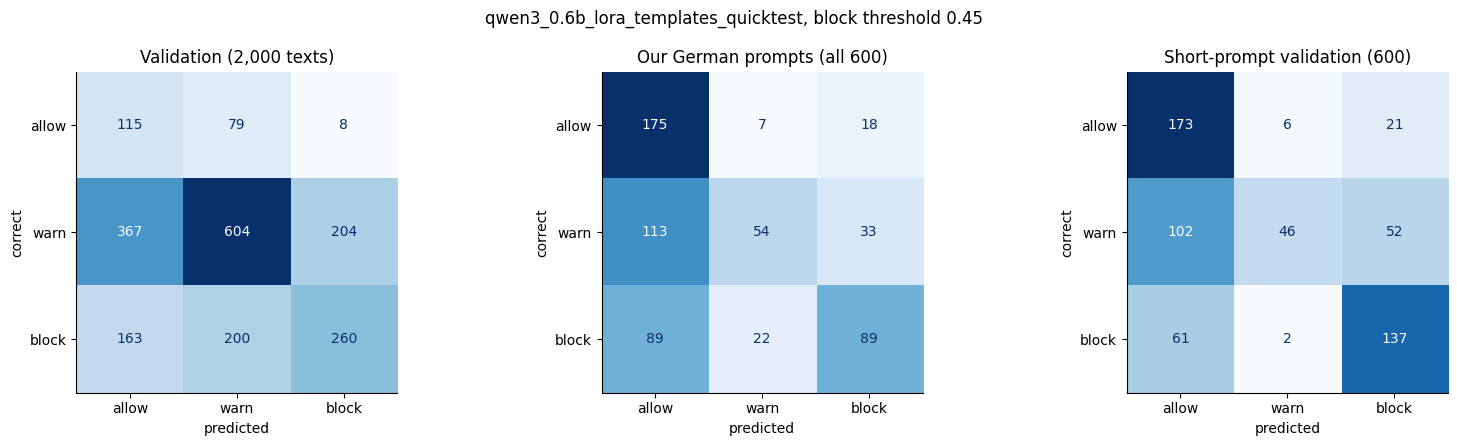

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ConfusionMatrixDisplay.from_predictions(val["decision"], val_pred, labels=CLASSES, ax=axes[0],
                                        cmap="Blues", colorbar=False, values_format=",d")
axes[0].set_title(f"Validation ({len(val):,} texts)")
ConfusionMatrixDisplay.from_predictions(expected_all, own_pred_all, labels=CLASSES, ax=axes[1],
                                        cmap="Blues", colorbar=False)
axes[1].set_title(f"Our German prompts (all {len(expected_all)})")
ConfusionMatrixDisplay.from_predictions(template_y, template_pred, labels=CLASSES, ax=axes[2],
                                        cmap="Blues", colorbar=False)
axes[2].set_title(f"Short-prompt validation ({len(template_val)})")
for ax in axes:
    ax.set_xlabel("predicted")
    ax.set_ylabel("correct")
fig.suptitle(f"{RUN_NAME}, block threshold {BLOCK_THRESHOLD}")
plt.tight_layout()
fig.savefig(OUT_DIR / "confusion_matrix.png", dpi=150)
plt.show()

## 12. Save the model

As for the encoder: the **LoRA adapter** (LoRA matrices + classification head), the tokenizer and
`promptguard_config.json`. New fields: `model_family = "llm"` (so `load_model` knows it is an LLM), `pad_token_id` and
`quantization`. Qwen3 itself is not saved: it is downloaded from Hugging Face at the fixed revision.

In [15]:
MODEL_DIR.mkdir(parents=True, exist_ok=True)
model.save_pretrained(MODEL_DIR)
tokenizer.save_pretrained(MODEL_DIR)
model_config = {
    "model_family": MODEL_FAMILY,
    "base_model": BASE_MODEL,
    "base_model_revision": BASE_MODEL_REVISION,
    "quantization": QUANTIZATION,
    "pad_token_id": tokenizer.pad_token_id,
    "classes": CLASSES,
    "max_length": MAX_LENGTH,
    "block_threshold": BLOCK_THRESHOLD,
    "split_fingerprint": SPLIT_FINGERPRINT,
    "harmless_fingerprint": HARMLESS_FINGERPRINT,
    "short_prompts_fingerprint": TEMPLATE_FINGERPRINT,
    "policy_version": POLICY_VERSION,
    "git_commit": GIT_COMMIT,
}
(MODEL_DIR / CONFIG_FILE).write_text(json.dumps(model_config, indent=2), encoding="utf-8")
size_mb = sum(f.stat().st_size for f in MODEL_DIR.iterdir()) / 1e6
print(f"Saved to {MODEL_DIR} ({size_mb:.1f} MB):", sorted(f.name for f in MODEL_DIR.iterdir()))

Saved to /content/AIOps_PromptGuard/models/qwen3_0.6b_lora_templates_quicktest (29.8 MB): ['README.md', 'adapter_config.json', 'adapter_model.safetensors', 'chat_template.jinja', 'promptguard_config.json', 'tokenizer.json', 'tokenizer_config.json']


## 13. Response time on the CPU

The same measurement as for the encoder: **CPU**, **one prompt at a time**, the same validation prompts, the
**saved** model loaded with `load_model` (the adapter is added into the base model with `merge_and_unload()`).
That also checks that saving worked: the reloaded model must give (almost) the same decisions on our own prompts.
With `1.7B` the model is reloaded **without** 4 bits (4 bits only work on the GPU), so a few decisions can differ.

**Only a guide value:** the Colab CPU is slow and shared. The fair comparison comes from the laptop:
`python src/measure_latency.py --download --log --run-name <RUN_NAME>`.

In [16]:
cpu_model, cpu_tokenizer, cpu_cfg = load_model(MODEL_DIR, device="cpu", merge=True)

# check: the saved model makes the same decisions as the model in memory
reloaded_pred = predict_with_threshold(predict_proba(cpu_model, cpu_tokenizer, own["prompt"].tolist(), MAX_LENGTH),
                                       CLASSES, cpu_cfg["block_threshold"])
print(f"Reloaded model: {(reloaded_pred == own_pred_all).sum()} of {len(own)} own prompts with the same decision")


def classify(prompt):
    p = predict_proba(cpu_model, cpu_tokenizer, [prompt], MAX_LENGTH, batch_size=1)
    return predict_with_threshold(p, CLASSES, BLOCK_THRESHOLD)[0]


for prompt in latency_sample[:20]:     # warm-up, not counted
    classify(prompt)
times = []
for prompt in latency_sample:
    start = time.perf_counter()
    classify(prompt)
    times.append((time.perf_counter() - start) * 1000)
COLAB_P50, COLAB_P95 = float(np.percentile(times, 50)), float(np.percentile(times, 95))
print(f"Colab CPU ({torch.get_num_threads()} threads, {len(times)} prompts): "
      f"p50 = {COLAB_P50:.1f} ms, p95 = {COLAB_P95:.1f} ms")
del cpu_model
_ = gc.collect()

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

[transformers] Qwen3ForSequenceClassification LOAD REPORT from: Qwen/Qwen3-0.6B
Key            | Status     | 
---------------+------------+-
lm_head.weight | UNEXPECTED | 
score.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Reloaded model: 598 of 600 own prompts with the same decision
Colab CPU (1 threads, 50 prompts): p50 = 1100.5 ms, p95 = 1486.5 ms


## 14. Comparison with SVM and encoder

Three columns with the **same rows** as `model_comparison_encoder.csv` of the encoder run. Nothing is estimated:

| Column | Where the numbers come from |
|---|---|
| SVM + short prompts | `reports/short_prompts_before_after.csv` (`short_prompts_retrain.ipynb`, run `svm_short`) |
| Encoder run 2 | MLflow run `xlmr_lora_benign_templates`: its table `model_comparison_encoder.csv` (ai4privacy, harmless and short-prompt rows) and its logged metrics `own_prompts_all_*` (own prompts, all 600; the table of that run has them only for v1) |
| Qwen3 | this run |

"own ..." rows = **all 600 own prompts**. Rows a model was not measured on show "n/a". Response times: SVM on the
laptop, encoder and Qwen3 on the Colab CPU (only a guide value, see chapter 13).

In [17]:
pii = evaluate(val["decision"][is_pii], val_pred[is_pii])
h = harmless_shares(val_pred[is_harmless])
qwen_column = {
    "block threshold": BLOCK_THRESHOLD,
    "ai4privacy recall block": round(pii["recall_block"], 3),
    "ai4privacy recall block (de)": round(recall_score(val["decision"][is_pii & is_de], val_pred[is_pii & is_de],
                                                       labels=["block"], average="macro"), 3),
    "ai4privacy macro F1": round(pii["macro_f1"], 3),
    "ai4privacy allow texts blocked": round(pii["false_block_allow"], 3),
    "real harmless prompts allowed": f"{h['harmless -> allow']:.1%}",
    "real harmless prompts blocked": f"{h['harmless -> block']:.1%}",
    **template_rows(template_pred, template_y),
    **own_rows(expected_all, own_pred_all, casual_all),          # all 600 own prompts
    "response time p95 (ms)": f"{COLAB_P95:.1f} (Colab CPU)",
}

# SVM trained with the same short prompts
svm_short = pd.read_csv(PROJECT_DIR / "reports" / "short_prompts_before_after.csv", index_col=0)[
    "SVM + short prompts (after)"].astype(str)
svm_short["response time p95 (ms)"] += " (laptop)"

# Encoder run 2: its comparison table (without its own-prompt rows, they are v1 only) + its metrics on all 600
# (downloaded next to the model folder, not into OUT_DIR, so it does not end up in the ZIP of chapter 16)
encoder_run = mlflow.get_run(ENCODER_RUN_ID)
encoder_csv = Path(mlflow.artifacts.download_artifacts(run_id=ENCODER_RUN_ID, artifact_path="model_comparison_encoder.csv",
                                                       dst_path=str(MODEL_DIR.parent / "encoder_run2_from_mlflow")))
encoder = pd.read_csv(encoder_csv, index_col=0)["Encoder run 2 (+ harmless + short prompts)"].astype(str)
encoder = encoder[~encoder.index.str.startswith("own")]
encoder = pd.concat([encoder, pd.Series(own_rows_from_metrics(encoder_run.data.metrics, "own_prompts_all_",
                                                              expected_all, casual_all))])
if "short val: warn let through (allow)" not in encoder.index:      # row missing in that table, but logged as metric
    encoder["short val: warn let through (allow)"] = f"{encoder_run.data.metrics['short_val_warn_to_allow']:.1%}"

QWEN_COLUMN_NAME = f"Qwen3-{MODEL_SIZE} + {'QLoRA' if QUANTIZATION else 'LoRA'} (+ harmless + short prompts)"
comparison = (pd.DataFrame({
    "SVM + short prompts": svm_short,
    "Encoder run 2 (+ harmless + short prompts)": encoder,
    QWEN_COLUMN_NAME: pd.Series(qwen_column).astype(str),
}).reindex(list(qwen_column)).fillna("n/a"))
comparison.to_csv(OUT_DIR / "model_comparison_llm.csv")
with pd.option_context("display.max_colwidth", 40):
    display(comparison)

,SVM + short prompts,Encoder run 2 (+ harmless + short prompts),Qwen3-0.6B + LoRA (+ harmless + short prompts)
block threshold,-0.4,0.5,0.45
ai4privacy recall block,0.956,0.993,0.417
ai4privacy recall block (de),0.953,0.993,0.224
ai4privacy macro F1,n/a,0.966,0.429
ai4privacy allow texts blocked,0.044,0.001,0.04
real harmless prompts allowed,91.0%,98.2%,92.9%
real harmless prompts blocked,2.2%,0.2%,3.6%
short val: correct,90.3%,100.0%,59.3%
short val: block caught,100.0%,100.0%,68.5%
short val: warn let through (allow),2.0%,0.0%,51.0%


## 15. MLflow

One run (`RUN_NAME`, e.g. `qwen3_0.6b_lora_templates`) in the experiment `promptguard`:

- **Params:** the same as the encoder run, plus `model_family = "llm"`, the number of weights (total / trainable),
  `quantization`, `gradient_accumulation_steps`, `quick_test` and the git commit.
- **Metrics:** the same names as the encoder (`val_*`, `val_argmax_*`, `own_prompts_*`, `own_prompts_v1/v2/all_*`,
  `short_val_*`, ...). **Plus every number of the comparison table as its own metric** (`own_accuracy`,
  `own_block_recall`, `own_warn_to_allow`, `own_harmless_blocked`, `pii_recall_block`, ...), so they can be shown as a bar
  chart in the MLflow chart view.
- **Artifacts:** the adapter + tokenizer (`model/`), the confusion matrices, `threshold_sweep.csv`,
  `own_prompts_wrong.csv`, `model_comparison_llm.csv`.

**Quick test:** the run gets the name `..._quicktest` and the tags `quick_test = true`, `candidate = false`. To hide it in
DagsHub, filter with `tags.quick_test != "true"`.

In [18]:
sweep.to_csv(OUT_DIR / "threshold_sweep.csv", index=False)

params = {
    "model": "llm_qlora" if QUANTIZATION else "llm_lora",
    "model_family": MODEL_FAMILY,
    "base_model": BASE_MODEL,
    "base_model_revision": BASE_MODEL_REVISION,
    "model_size": MODEL_SIZE,
    "quantization": QUANTIZATION or "none",
    "n_params_total": N_PARAMS_TOTAL,
    "n_params_trainable": N_TRAINABLE,
    "lora_r": LORA_R,
    "lora_alpha": LORA_ALPHA,
    "lora_dropout": LORA_DROPOUT,
    "lora_target_modules": ",".join(LORA_LAYERS[BASE_MODEL]["target_modules"]),
    "learning_rate": LEARNING_RATE,
    "epochs": EPOCHS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "batch_size": BATCH_SIZE,
    "gradient_accumulation_steps": GRAD_ACCUM,
    "max_length": MAX_LENGTH,
    "train_size": len(train_sample),
    "n_per_class_and_language": N_PER_CLASS_AND_LANGUAGE,
    "n_harmless_train": N_HARMLESS_TRAIN,
    "train_data": TRAIN_DATA,
    "quick_test": QUICK_TEST,
    "val_size": len(val),
    "device": DEVICE_NAME,
    "seed": SEED,
    "block_threshold": "argmax" if BLOCK_THRESHOLD is None else BLOCK_THRESHOLD,
    "threshold_reason": threshold_reason,
    "split_fingerprint": SPLIT_FINGERPRINT,
    "harmless_fingerprint": HARMLESS_FINGERPRINT,
    "short_prompts_fingerprint": TEMPLATE_FINGERPRINT,
    "n_short_train": sum(N_TEMPLATE_TRAIN.values()),
    **{f"n_short_train_{c}": N_TEMPLATE_TRAIN.get(c, 0) for c in CLASSES},
    "compared_with_run_id": ENCODER_RUN_ID,
    "policy_version": POLICY_VERSION,
    "git_commit": GIT_COMMIT,
    "python_version": platform.python_version(),
    "torch_version": torch.__version__,
    "transformers_version": transformers.__version__,
    "peft_version": peft.__version__,
}

# every number of the comparison table as a single metric (for bar charts in MLflow)
own_all = metrics_own_by_version["all"]
table_metrics = {
    "pii_recall_block": pii["recall_block"],
    "pii_recall_block_de": recall_score(val["decision"][is_pii & is_de], val_pred[is_pii & is_de],
                                        labels=["block"], average="macro"),
    "pii_macro_f1": pii["macro_f1"],
    "pii_allow_blocked": pii["false_block_allow"],
    "harmless_allowed": h["harmless -> allow"],
    "harmless_blocked": h["harmless -> block"],
    # short_val_accuracy / _recall_block / _warn_to_allow / _false_block_allow: logged below with metrics_template
    "own_accuracy": own_all["accuracy"],                       # own prompts, all 600
    "own_block_recall": own_all["recall_block"],
    "own_casual_block_recall": own_all["casual_recall_block"],
    "own_harmless_blocked": own_all["false_block_allow"],
    "own_warn_to_allow": own_all["warn_to_allow"],
}
if BLOCK_THRESHOLD is not None:              # None = argmax rule, then there is no threshold to log
    table_metrics["block_threshold"] = BLOCK_THRESHOLD

with mlflow.start_run(run_name=RUN_NAME) as run:
    mlflow.set_tags({"milestone": "M2", "experiment_part": "C_llm_lora", "model_family": MODEL_FAMILY,
                     "quick_test": str(QUICK_TEST).lower(), "candidate": "false" if QUICK_TEST else "true"})
    mlflow.log_params(params)
    mlflow.log_metrics({f"val_{k}": v for k, v in metrics_val.items()})
    mlflow.log_metrics({f"val_argmax_{k}": v for k, v in metrics_val_argmax.items()})
    mlflow.log_metrics({f"own_prompts_{k}": v for k, v in metrics_own.items()})        # v1, as in the encoder runs
    mlflow.log_metrics({f"own_prompts_{name}_{k}": v
                        for name, m in metrics_own_by_version.items() for k, v in m.items()})
    mlflow.log_metrics({f"short_val_{k}": v for k, v in metrics_template.items()})
    mlflow.log_metrics(table_metrics)
    mlflow.log_metrics({
        "colab_cpu_latency_p50_ms": COLAB_P50,   # laptop values come from src/measure_latency.py --log
        "colab_cpu_latency_p95_ms": COLAB_P95,
        "epochs_trained": EPOCHS_TRAINED,
        "train_minutes": TRAIN_MINUTES,
        "trainable_params": N_TRAINABLE,
        "total_params": N_PARAMS_TOTAL,
        "train_cut_off_share": float(cut_off),
    })
    for _, row in history.iterrows():            # learning curve: validation macro F1 per epoch
        mlflow.log_metric("epoch_val_macro_f1", row["eval_macro_f1"], step=int(round(row["epoch"])))
    mlflow.log_artifacts(str(MODEL_DIR), artifact_path="model")
    for name in ["confusion_matrix.png", "own_prompts_wrong.csv", "threshold_sweep.csv", "model_comparison_llm.csv"]:
        mlflow.log_artifact(str(OUT_DIR / name))
    RUN_ID = run.info.run_id
print("Logged to MLflow, run id:", RUN_ID)

🏃 View run qwen3_0.6b_lora_templates_quicktest at: https://dagshub.com/annihlj/AIOps_PromptGuard.mlflow/#/experiments/0/runs/01f3e0164fce422e82e2181315e34c4a
🧪 View experiment at: https://dagshub.com/annihlj/AIOps_PromptGuard.mlflow/#/experiments/0
Logged to MLflow, run id: 01f3e0164fce422e82e2181315e34c4a


## 16. Check MLflow and download a local copy

The same as in the encoder notebook:

**1. Check.** We ask MLflow (DagsHub) which files the run really has under `model/`, download the adapter again and
compare it byte by byte (SHA-256 hash) with the local file. If anything is missing or different, the cell stops
with an error: then run chapter 15 again.

**2. Local copy.** Model folder and result tables are packed into one ZIP file and downloaded by the browser.
Unpack it on the laptop into the folder `models/` of the project; then `python src/measure_latency.py --log --run-name <RUN_NAME>`
finds the model in `models/<RUN_NAME>/` without downloading it again.
If the browser does not start the download: folder icon on the left → `/content/<RUN_NAME>.zip` → three dots →
*Download*. Colab deletes `/content` when the session ends, so do it before closing.

**3. Google Drive** (optional, `USE_DRIVE` in chapter 2): an extra copy.

In [19]:
import hashlib
import tempfile
import zipfile


def sha256(path):
    # "fingerprint" of a file: same content = same hash
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


# ---- 1) Did the model really arrive in MLflow?
client = mlflow.MlflowClient()
remote_files = sorted(Path(f.path).name for f in client.list_artifacts(RUN_ID, "model"))
local_files = sorted(f.name for f in MODEL_DIR.iterdir())
print("In MLflow under model/:", remote_files)
missing = sorted(set(local_files) - set(remote_files))
assert not missing, f"Missing in MLflow: {missing}. Run chapter 15 again."

with tempfile.TemporaryDirectory() as tmp:
    downloaded = mlflow.artifacts.download_artifacts(
        run_id=RUN_ID, artifact_path="model/adapter_model.safetensors", dst_path=tmp)
    assert sha256(downloaded) == sha256(MODEL_DIR / "adapter_model.safetensors"), \
        "The adapter in MLflow is different from the local one. Run chapter 15 again."
print(f"OK: all {len(local_files)} model files are in MLflow, the adapter is identical (run id {RUN_ID})")

# ---- 2) Local copy: one ZIP with the model folder and the result tables
zip_path = (Path("/content") if IN_COLAB else MODEL_DIR.parent) / f"{RUN_NAME}.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in [MODEL_DIR, OUT_DIR]:
        for f in sorted(folder.rglob("*")):
            # path inside the ZIP: <RUN_NAME>/... and <RUN_NAME>_outputs/...
            z.write(f, f.relative_to(MODEL_DIR.parent))
print(f"ZIP: {zip_path} ({zip_path.stat().st_size / 1e6:.1f} MB)")
if IN_COLAB:
    from google.colab import files
    files.download(str(zip_path))      # the browser downloads the file

# ---- 3) Optional: copy to Google Drive
if IN_COLAB and USE_DRIVE:
    shutil.copytree(MODEL_DIR, DRIVE_DIR / RUN_NAME, dirs_exist_ok=True)
    shutil.copytree(OUT_DIR, DRIVE_DIR / f"{RUN_NAME}_outputs", dirs_exist_ok=True)
    print("Copied to", DRIVE_DIR)

In MLflow under model/: ['README.md', 'adapter_config.json', 'adapter_model.safetensors', 'chat_template.jinja', 'promptguard_config.json', 'tokenizer.json', 'tokenizer_config.json']


OK: all 7 model files are in MLflow, the adapter is identical (run id 01f3e0164fce422e82e2181315e34c4a)
ZIP: /content/qwen3_0.6b_lora_templates_quicktest.zip (19.2 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 17. Conclusion

*To be written after the real run (`QUICK_TEST = False`), from the table in chapter 14 and the laptop response time
(`python src/measure_latency.py --download --log --run-name qwen3_0.6b_lora_templates`).*

Questions to answer:
1. Does Qwen3 catch more of our own **block** prompts than encoder run 2 (179 of 200)? Especially the passwords in
   everyday style (`own_prompts_wrong.csv`, column `category`)?
2. Does it keep the strengths of the encoder (few warn prompts let through, few false alarms)?
3. How much slower is it on the laptop CPU (encoder: about 85 ms p95, target < 100 ms)? Is the gain worth it?

**Limitations (known before the run)**
- The same as encoder run 2: a sample of about 46,000 texts, validation used for early stopping **and** the threshold,
  only 600 own prompts (one prompt = 0.5 points on 200 prompts).
- Other hyperparameters than the encoder (learning rate 1e-4 instead of 2e-4, LoRA on 4 instead of 2 projections):
  chosen in advance for an LLM, not tuned. A difference between the models can partly come from these settings.
- Qwen3 supports 100+ languages (model card), but a model with 0.6 B weights has limited knowledge per language;
  how well it knows German, French and Italian we only see in the results (`val_de_recall_block`, own prompts).
- GPU training is not 100 % bit-identical between runs. The saved adapter in MLflow is the reference.